# 7. Proportions, corrections, and what a null result means

*Part of the [broadlisten](https://github.com/InteractionDataLab/broad-listening/tree/main/code)
stage-by-stage examples. Every number and figure below was produced by running
this notebook on the synthetic corpus in `broadlisten.sample`, which is
generated from templates and contains no participant data.*

A theme's prevalence is a proportion, and a proportion without an interval
invites a reader to treat 3 of 5 and 300 of 500 as the same claim.

In [1]:
from IPython.display import Image

def png(fig, w=900, h=480):
    """Render a figure as a static PNG.

    GitHub's notebook viewer does not run Plotly, so an interactive figure is a
    blank cell to anyone reading this on the web. A PNG is visible to everyone.
    """
    return Image(fig.to_image(format="png", width=w, height=h, scale=2))

In [2]:
from broadlisten.stats import wilson_interval

for k, n in [(3, 5), (30, 50), (300, 500)]:
    point, lo, hi = wilson_interval(k, n)
    print(f"{k:4d} of {n:4d} = {point:.1%}  [{lo:.1%}, {hi:.1%}]  "
          f"width {100 * (hi - lo):.1f} pp")

   3 of    5 = 60.0%  [23.1%, 88.2%]  width 65.2 pp
  30 of   50 = 60.0%  [46.2%, 72.4%]  width 26.2 pp
 300 of  500 = 60.0%  [55.6%, 64.2%]  width 8.6 pp


## The same three, drawn

The bars are identical. The intervals are not, and that is the whole point.

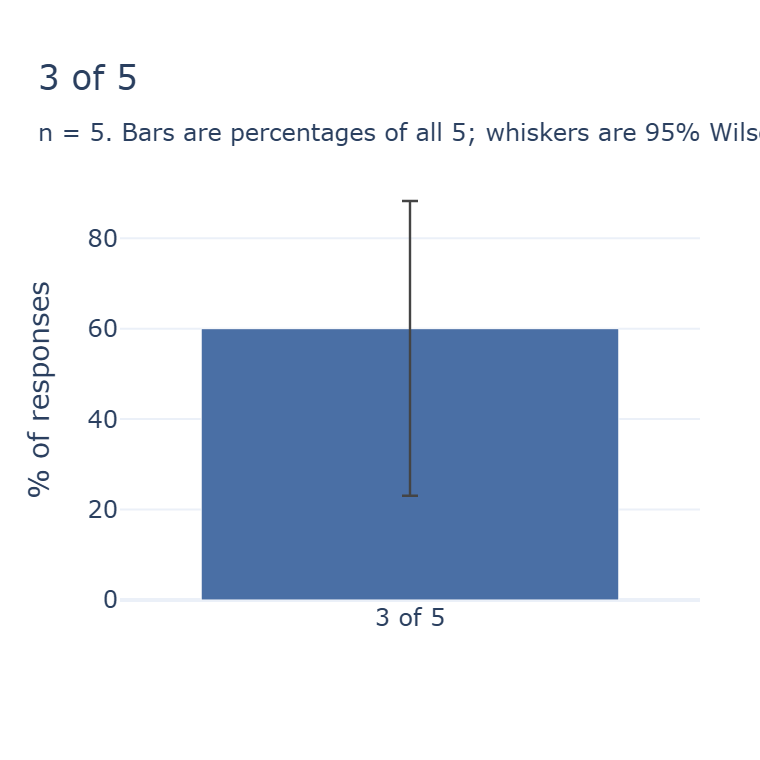

In [3]:
from broadlisten.explore import category_bars

png(category_bars({"3 of 5": 3}, total=5, title="3 of 5"), w=380, h=380)

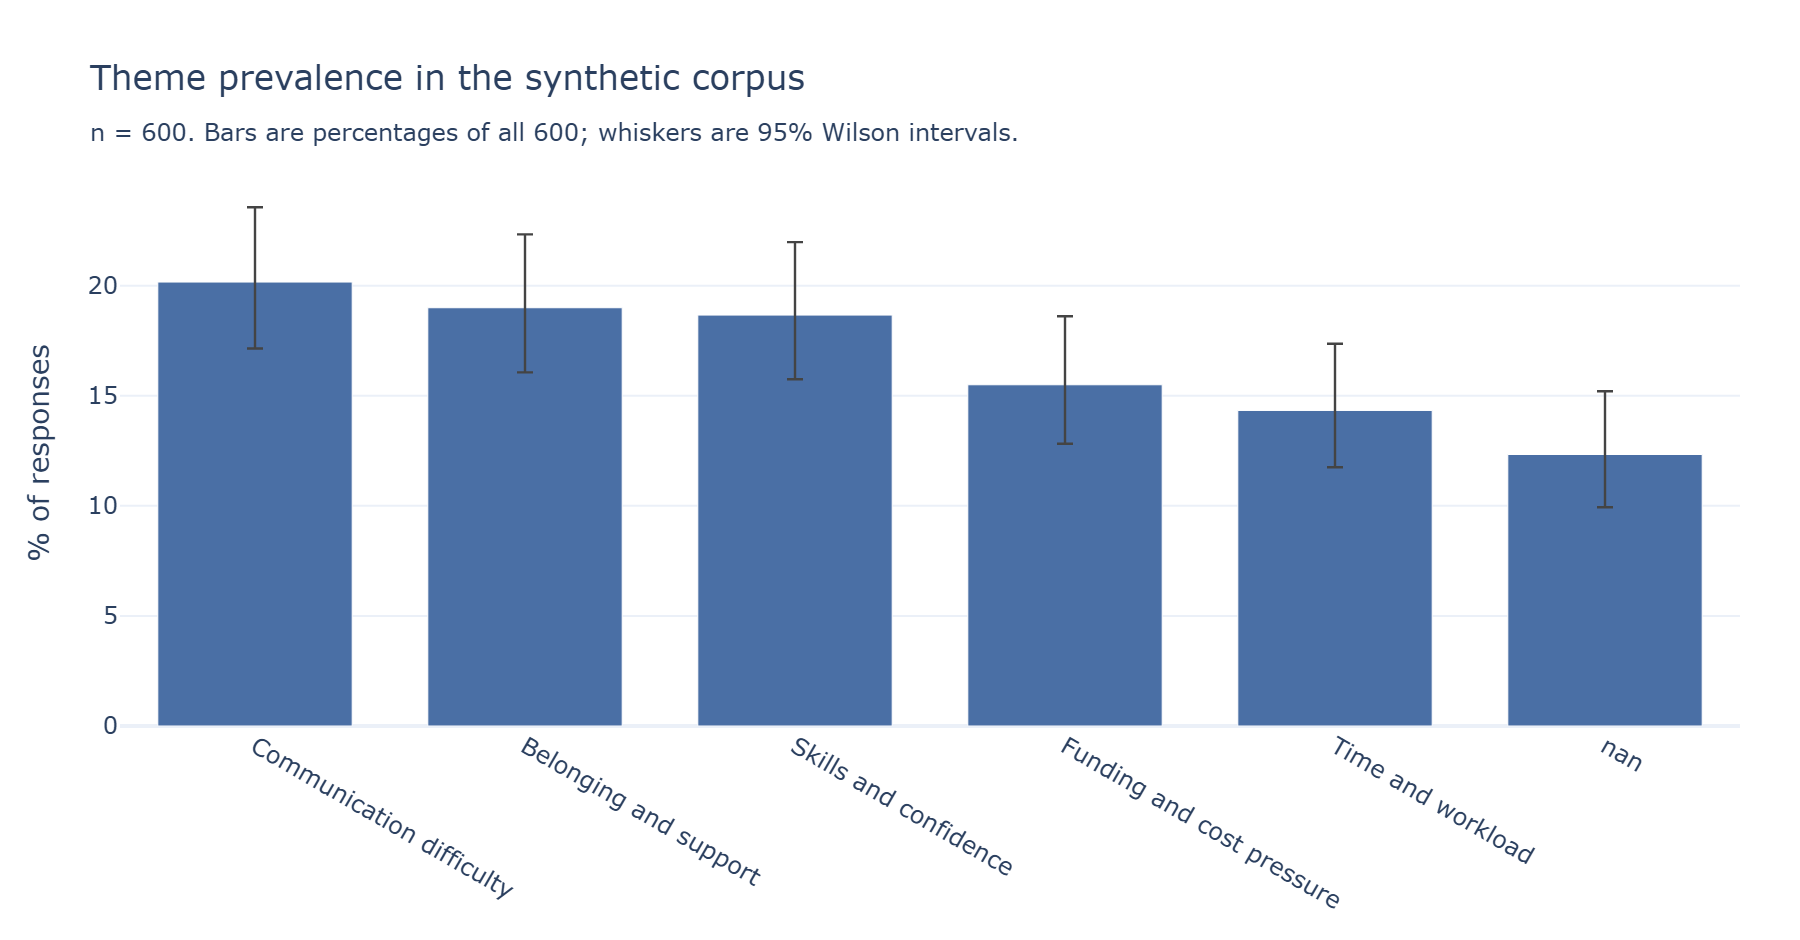

In [4]:
import numpy as np
from broadlisten.sample import sample_corpus
from broadlisten.explore import category_bars

corpus = sample_corpus(seed=0)
counts = corpus.planted_theme.value_counts(dropna=False)
counts.index = [str(i) if i is not None else "no theme" for i in counts.index]
png(category_bars(counts.to_dict(),
                  title="Theme prevalence in the synthetic corpus"), h=470)

## Correcting for many tests

Scanning many themes at once means some will look significant by chance.
Benjamini-Hochberg controls the false discovery rate.

In [5]:
from broadlisten.stats import bh_fdr

p = [0.001, 0.008, 0.02, 0.04, 0.2, 0.5, 0.9]
q = bh_fdr(p)
print(f"{'p':>7} {'q (BH)':>8}  significant at q<0.05")
for pi, qi in zip(p, q):
    print(f"{pi:7.3f} {qi:8.3f}  {qi < 0.05}")

      p   q (BH)  significant at q<0.05
  0.001    0.007  True
  0.008    0.028  True
  0.020    0.047  True
  0.040    0.070  False
  0.200    0.280  False
  0.500    0.583  False
  0.900    0.900  False


**But a correction does not repair a violated assumption.** If people
inside a team are not independent draws, a team-level split creates a real
participant-level difference, and BH has nothing to correct away. The fix is to
test at the unit the grouping was applied to. `examples/04_statistics.py`
demonstrates this by rerunning a scan 150 times under a known null.

## Effect size, and what a null means

"No difference" says nothing until you know what size of difference the design
could have detected.

In [6]:
from broadlisten.stats import cliffs_delta, minimum_detectable_effect, tost_equivalence

a = np.random.default_rng(0).normal(0.0, 1, 60)
b = np.random.default_rng(1).normal(0.3, 1, 60)
print(f"Cliff's delta: {cliffs_delta(a, b):+.3f}")

mde = minimum_detectable_effect(60, 60, base_rate=0.3)
print("\nwith 60 per group at a base rate of 30%, the smallest difference")
print(f"detectable at 80% power is {mde:.1f} percentage points")
print("so 'no difference' here means 'no difference larger than that'")

Cliff's delta: -0.117



with 60 per group at a base rate of 30%, the smallest difference
detectable at 80% power is 23.0 percentage points
so 'no difference' here means 'no difference larger than that'


In [7]:
eq = tost_equivalence(18, 60, 20, 60, margin_pp=15)
print("TOST equivalence, margin 15 pp:")
for k, v in eq.items():
    print(f"  {k}: {v}")

TOST equivalence, margin 15 pp:
  difference_pp: -3.3333333333333326
  lo_pp: -16.996088973478514
  hi_pp: 10.502185477979294
  margin_pp: 15.0
  equivalent: False
  testable: True


## Whole-profile comparison

A group can differ as a whole profile while no single theme does. PERMANOVA asks
that different question.

In [8]:
from broadlisten.stats import permanova

rng = np.random.default_rng(0)
profiles = rng.random((40, 6)) < 0.3
groups = ["a"] * 20 + ["b"] * 20
result = permanova(profiles.astype(float), groups, n_perm=999, seed=42)
# "null" holds the whole permutation distribution, so print the rest.
for k in ("pseudo_F", "R2", "p_perm", "n", "levels", "n_perm"):
    print(f"  {k}: {result[k]}")

  pseudo_F: 0.33644290374585895
  R2: 0.008776059494893436
  p_perm: 0.906
  n: 40
  levels: 2
  n_perm: 999


---

That is the whole pipeline, stage by stage. The full study that produced these
methods is in [`analysis/`](../../analysis), and the interactive figures from it
are in [`docs/`](../../docs).